# Credit card fraud detection

## Objective:
To build a simple model that can identify fradulent credit card transactions.

## Dataset:
The dataset was downloaded from Kaggle (https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data?select=creditcard.csv). It contains numerical PCA-transformed features, transaction amount, elapsed transaction time, and a fraud label.

- Class 0: legitimate transaction
- Class 1: fraudulent transaction

## Approach
This code will explore the data, train a model using logistic regression, and evaluate its precision, recall, and mistakes.

# Import the required libraries, and load the data:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

df = pd.read_csv("creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Inspect the data:

In [17]:
# Number of rows and columns in the dataset:
print("Number of rows and columns in the dataset:", df.shape)

# Total number of missing values in the dataset:
print("Total number of missing values in the dataset:", df.isnull().sum().sum())

# Total number of duplicate rows in the dataset:
print("Total number of duplicate rows in the dataset:", df.duplicated().sum())

Number of rows and columns in the dataset: (284807, 31)
Total number of missing values in the dataset: 0
Total number of duplicate rows in the dataset: 1081


# Exploratory data analysis (EDA):

In [18]:
# How common is fraud in the dataset?
counts = df['Class'].value_counts().sort_index()


summary = pd.DataFrame({'Class': counts.index, 
                        'Count': counts.values,
                        'Percentage (%)': (counts.values / len(df)) * 100
})


summary.index = ["Legitimate", "Fraudulent"]

summary.round(3)


,Class,Count,Percentage (%)
Legitimate,0,284315,99.827
Fraudulent,1,492,0.173


# Plot the counts:

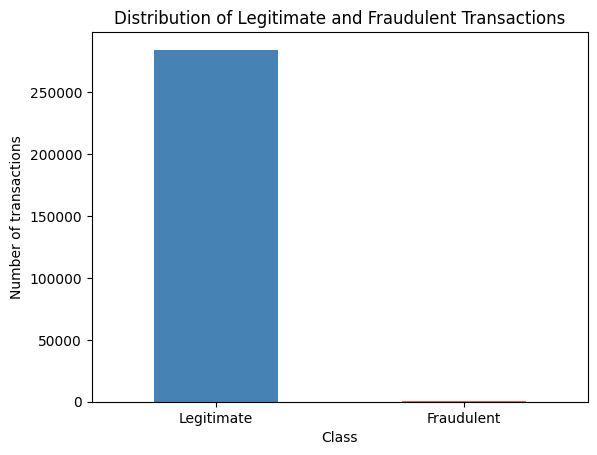

In [19]:
counts.plot.bar(color=["steelblue", "tomato"])

plt.xticks([0, 1], ["Legitimate", "Fraudulent"], rotation=0)
plt.ylabel("Number of transactions")
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.show()

### Key Observation:
Fraudulent transactions represent only 0.17% of the total transactions in our dataset. Therefore, a high overall accuracy alone wouldn't demonstrate that the model can detect fradulent transactions.

# How do transaction amounts differ?

In [20]:
df.groupby("Class")["Amount"].agg(["count", "mean", "std", "median", "min", "max"]).round(2)

,count,mean,std,median,min,max
Class,,,,,,
0,284315,88.29,250.11,22.00,0.0,25691.16
1,492,122.21,256.68,9.25,0.0,2125.87


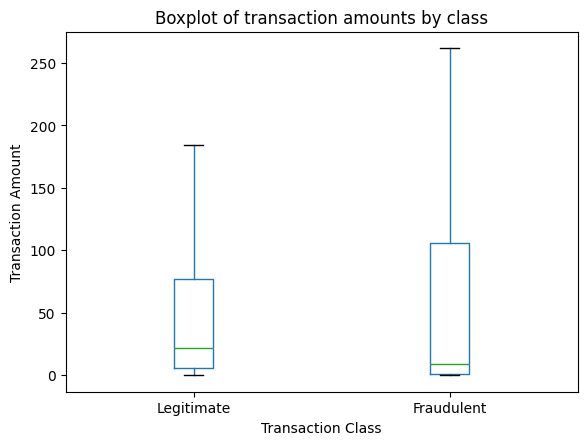

In [21]:
df.boxplot(column="Amount", by="Class", grid=False, showfliers=False)

plt.xticks([1, 2], ["Legitimate", "Fraudulent"], rotation=0)
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.title("Boxplot of transaction amounts by class")
plt.suptitle("")
plt.show()

### NOTE: For improved readability, extreme values have been hidden in the above figure, not removed from the dataset.

# Train a model:

In [4]:
# Import the necessary libraries for model training and evaluation:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


df = df.sort_values("Time").reset_index(drop=True)

# Keep transactions with the same timestamp together:
cutoff = df["Time"].iloc[int(len(df) * 0.8)]

# Split the dataset into training and testing sets based on the cutoff timestamp:
train = df[df["Time"] < cutoff]
test = df[df["Time"] >= cutoff]

x_train = train.drop(columns="Class")
y_train = train["Class"]

x_test = test.drop(columns="Class")
y_test = test["Class"]

# Create a pipeline that standardizes the features and trains a logistic regression model with balanced class weights:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000)
)

model.fit(x_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [5]:
print("Training transactions:", len(train))
print("Testing transactions:", len(test))

print("Training fraudulent transactions:", y_train.sum())
print("Testing fraudulent transactions:", y_test.sum())

Training transactions: 227845
Testing transactions: 56962
Training fraudulent transactions: 417
Testing fraudulent transactions: 75


# Evaluate the model:

In [ ]:
# Check the precision, recall, and F1-score (mistakes) of the model on the test set:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

predictions = model.predict(x_test)

print(classification_report(
    y_test, 
    predictions, 
    target_names = ["Legitimate", "Fraudulent"],
    digits = 3,
    zero_division = 0
))

              precision    recall  f1-score   support

  Legitimate      1.000     0.985     0.992     56887
  Fraudulent      0.071     0.893     0.131        75

    accuracy                          0.984     56962
   macro avg      0.535     0.939     0.562     56962
weighted avg      0.999     0.984     0.991     56962



# Plot the confusion matrix:

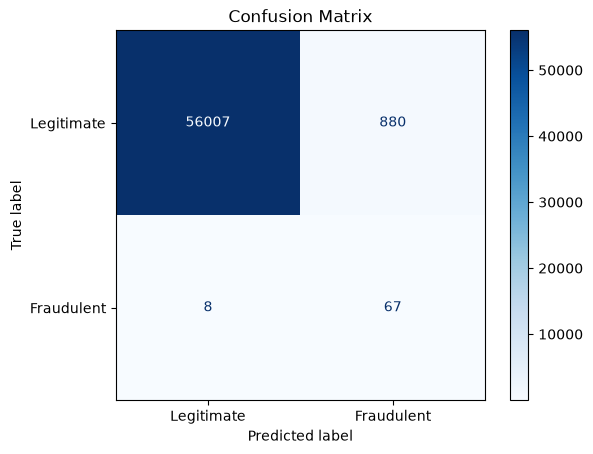

In [7]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions, 
    display_labels = ["Legitimate", "Fraudulent"],
    cmap = "Blues",
    values_format = "d"
)

plt.title("Confusion Matrix")
plt.show()

### Model evaluation:
The model detected 67 of the 75 fraudulent transactions in the test set,
achieving fraud recall of 89.3%. It missed 8 fraudulent transactions.

However, fraud precision was only 7.1%. This means that approximately
7 out of every 100 transactions flagged as fraud were actually fraudulent;
the remaining 93 were legitimate transactions.

The model therefore catches most fraud cases, but generates many false
alarms. This could create a substantial workload if every flagged
transaction required manual review.

Although overall accuracy was 98.4%, accuracy alone is misleading here
because the vast majority of transactions are legitimate. Precision and
recall provide a clearer picture of the model's fraud-detection performance.

Overall, the model prioritizes catching fraud over keeping false alerts low.

# Precision-recall curve:

Average precision: 0.762


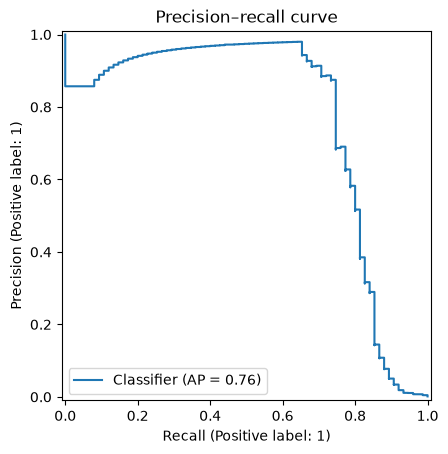

In [9]:
from sklearn.metrics import(
    average_precision_score,
    PrecisionRecallDisplay
)

scores = model.predict_proba(x_test)[:, 1]

print(
    "Average precision:",
    round(average_precision_score(y_test, scores), 3)
)

PrecisionRecallDisplay.from_predictions(y_test, scores)
plt.title("Precision–recall curve")
plt.show()

## Key findings:
- Fraud accounted for approximately 0.132% of transactions in the test set (75 out of 56,962 transactions).

- The model detected 67 of 75 fraud cases in the test period, and missed 8.

- Fraud precision was 7.1% and fraud recall was 89.3%.

- The model incorrectly flagged 880 legitimate transactions.


## Conclusion
The model detected most fraudulent transactions, but generated many false alarms. It identified approximately 9 out of every 10 fraud cases, yet only about 7 out of every 100 transactions flagged as fraud were
actually fraudulent.

These results show a trade-off: the model catches a large proportion of fraud, but its alerts would require substantial review. High recall alone does not make the model suitable for automatically blocking transactions.


## Limitations
- The PCA-transformed features do not have clear business meanings, limiting explanations of why individual transactions were flagged.

- Results reflect this dataset and evaluation period, not necessarily future real-world transactions.

- False alerts and missed fraudulent transactions have different consequences, but this project doesn't estimate their financial or operational costs.

- The test set contained only 75 fraud cases, so a few additional detections or misses would noticeably change the reported recall.

- This is a learning project, not a production fraud-detection system.